# Coverage repair: development evaluation
This notebook evaluates the repaired agent hand-offs on development data only.
Original D33 results are preserved. This is a development comparison, not new unseen-test evidence.
API keys come from the ignored local `.env`. All response commands are inert recommendations.

In [1]:
import asyncio, hashlib, json, os, pathlib, shutil, subprocess, sys, zipfile
ROOT = pathlib.Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
os.chdir(ROOT)
for name in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS']:
    os.environ[name] = '1'
sys.path.insert(0, str(ROOT / 'src'))
from dotenv import load_dotenv
load_dotenv(ROOT / '.env', override=False)
if not os.environ.get('GEMINI_API_KEY'):
    raise RuntimeError('Add GEMINI_API_KEY privately in .env before running.')
from cyberagents.config import CONFIG
RUN = ROOT / 'outputs/revision_v2'
RUN.mkdir(parents=True, exist_ok=True)
print('Revision:', CONFIG['system_revision'])
print('Model:', CONFIG['llm']['model'])
print('Development seed:', CONFIG['dev_seed'])


Revision: coverage-v2
Model: gemini-3.5-flash-lite
Development seed: 42


## Regression and offline checks

In [2]:
checked = subprocess.run([sys.executable, '-m', 'pytest', '-m', 'not live', '-q'],
                         cwd=ROOT, text=True, capture_output=True)
print(checked.stdout.splitlines()[-1] if checked.stdout else checked.stderr)
if checked.returncode:
    print(checked.stdout, checked.stderr)
    raise RuntimeError('Offline checks failed')


82 passed, 1 deselected, 26 warnings in 52.49s


## Identical development inputs and pinned knowledge base

In [3]:
source_data = ROOT / 'outputs/seed42'
if not (RUN / 'seed42').exists():
    shutil.copytree(source_data, RUN / 'seed42')
for name in ['auth.log', 'access.log', 'firewall.csv', 'asset_inventory.json', 'ground_truth.json']:
    # Byte-preserving copy check only; labels are interpreted solely by the evaluator.
    assert hashlib.sha256((source_data / name).read_bytes()).digest() == hashlib.sha256((RUN / 'seed42' / name).read_bytes()).digest()
from cyberagents.attack_kb import build_kb
kb = build_kb()
print('Input bytes match the original development dataset.')


Input bytes match the original development dataset.


## Repaired live agent run

In [4]:
from cyberagents.pipeline import run_system
# Refresh this development output; the provider response cache still reuses identical calls.
s3 = await asyncio.to_thread(run_system, 'S3', 42, output_dir=RUN, live=True, force=True)
print(json.dumps({key: s3[key] for key in ['execution', 'runtime_s', 'llm_calls', 'cache_hits', 'coverage']}, indent=2))
if not s3['coverage']['complete']:
    raise RuntimeError('Incomplete agent coverage; inspect revision_v2/stages before claiming success.')


{
  "execution": "live",
  "runtime_s": 115.71899999992456,
  "llm_calls": 3,
  "cache_hits": 1,
  "coverage": {
    "complete": true,
    "unresolved": {}
  }
}


## Measured development comparison

,detection_recall,false_positives,mapping_accuracy,a6_stages,invalid_evidence_refs,nonexistent_technique_ids,unretrieved_technique_ids,runtime_s,llm_calls
version,,,,,,,,,
D33 original,0.166667,0,0.8,5,0,0,0,113.719,4
V2 development,1.000000,0,0.9,5,0,0,0,115.719,3


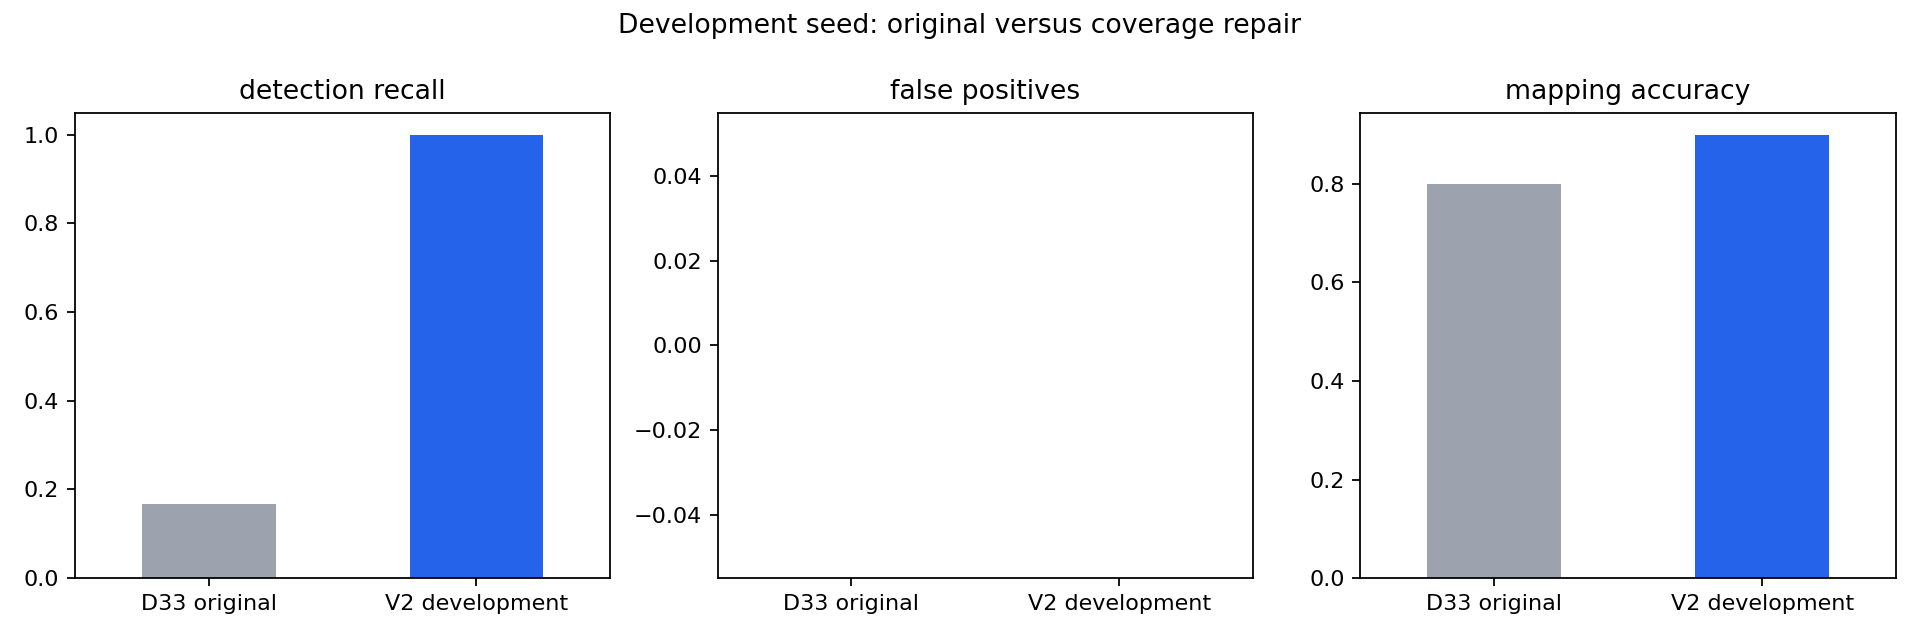

Development comparison only; previously exposed held-out seeds were not rerun.


In [5]:
from cyberagents.evaluate import evaluate_saved, render_results
import pandas as pd
from IPython.display import display, Image, Markdown
baseline = json.loads((ROOT / 'outputs/metrics_S3_seed42.json').read_text())
revised = evaluate_saved(RUN / 'S3_seed42.json', kb, output_dir=RUN)
columns = ['detection_recall', 'false_positives', 'mapping_accuracy', 'a6_stages',
           'invalid_evidence_refs', 'nonexistent_technique_ids', 'unretrieved_technique_ids', 'runtime_s', 'llm_calls']
comparison = pd.DataFrame([{**{key: row[key] for key in columns}, 'version': label}
    for label, row in [('D33 original', baseline), ('V2 development', revised)]]).set_index('version')
comparison.to_csv(RUN / 'development_comparison.csv')
display(comparison)
render_results(RUN)
import matplotlib.pyplot as plt
figure, axes = plt.subplots(1, 3, figsize=(12, 4))
for axis, metric in zip(axes, ['detection_recall', 'false_positives', 'mapping_accuracy']):
    comparison[metric].plot.bar(ax=axis, rot=0, color=['#9ca3af', '#2563eb'])
    axis.set_title(metric.replace('_', ' '))
    axis.set_xlabel('')
figure.suptitle('Development seed: original versus coverage repair')
figure.tight_layout()
figure.savefig(RUN / 'development_comparison.png', dpi=160)
plt.close(figure)
display(Image(filename=str(RUN / 'development_comparison.png')))
print('Development comparison only; previously exposed held-out seeds were not rerun.')


## Real incident report

In [6]:
from cyberagents.evaluate import render_a6_demo
try:
    report = render_a6_demo(RUN / 'S3_seed42.json', RUN / 'demo_incident.md', output_dir=RUN)
    display(Markdown(report))
except ValueError as error:
    print(str(error))


# External Reconnaissance, Compromise, Privilege Escalation, and Data Exfiltration

Synthetic-data demonstration; recommendations only.

Severity: critical | Confidence: 0.95

Linked chain of activity showing scanning, brute force, successful login, root shell, and outbound transfer originating from source IP 203.0.113.75 against ssh-srv.

## Timeline

- 2026-10-16T20:37:10Z: T1595.001 — Sequential port connection attempts from external IP 203.0.113.75 against ssh-srv.
- 2026-10-16T20:47:10Z: T1110.001 — Password guessing attempts against the deploy account from external IP 203.0.113.75.
- 2026-10-16T20:52:10Z: T1078 — Successful SSH authentication for user deploy from external IP 203.0.113.75.
- 2026-10-16T20:54:10Z: T1548.003 — User deploy invoked root shell via sudo for privilege escalation.
- 2026-10-16T21:07:10Z: T1041 — Large data transfer from ssh-srv to external IP on non-standard port 4444.

## Recommended actions

- P1: Isolate host from network (target: ssh-srv)

```text
ip link set eth0 down
```

- P1: Block attacker IP (target: 203.0.113.75)

```text
iptables -A INPUT -s 203.0.113.75 -j DROP
```

- P1: Terminate active sessions for user deploy (target: deploy)

```text
pkill -u deploy
```


## ATT&CK mitigations

- M1056 Pre-compromise → T1595.001
- M1051 Update Software → T1110.001
- M1032 Multi-factor Authentication → T1110.001
- M1027 Password Policies → T1110.001
- M1036 Account Use Policies → T1110.001
- M1027 Password Policies → T1078
- M1018 User Account Management → T1078
- M1026 Privileged Account Management → T1078
- M1032 Multi-factor Authentication → T1078
- M1013 Application Developer Guidance → T1078
- M1017 User Training → T1078
- M1015 Active Directory Configuration → T1078
- M1036 Account Use Policies → T1078
- M1022 Restrict File and Directory Permissions → T1548.003
- M1028 Operating System Configuration → T1548.003
- M1026 Privileged Account Management → T1548.003
- M1031 Network Intrusion Prevention → T1041
- M1057 Data Loss Prevention → T1041

Evaluation: this incident covers 5 of the A6 stages.


## Original results preserved

In [7]:
with zipfile.ZipFile(ROOT / 'outputs/frozen_d33_snapshot.zip') as snapshot:
    manifest = json.loads(snapshot.read('frozen_manifest.json'))
    original_files = {name: digest for name, digest in manifest['files'].items()
                      if name.startswith(('outputs/', 'notebooks/'))}
    for name, digest in original_files.items():
        assert hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == digest, name
print('Original output/notebook files unchanged:', len(original_files))
print('No revised held-out evaluation or new freeze was performed.')


Original output/notebook files unchanged: 69
No revised held-out evaluation or new freeze was performed.
